In [12]:
# we can do the label encoding and on hot using tf.keras.layers.StringLookup and tf.keras.layers.CategoryEncoding
    

In [13]:
# Convert labels to ints and ints to categories

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

y_categorical  = to_categorical(y_encoded , num_classes=4)

print(y_categorical[6000:6005])

[[0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]
 [0. 0. 0. 1.]]


In [14]:
#normalization 

#saving image before 
image_before = x[0].copy()

x = x.astype('float32') / 255.0

image_after = x[0]

print("Before:", image_before.min(), image_before.max())
print("After:", image_after.min(), image_after.max())

Before: 0 245
After: 0.0 0.9607843


In [15]:
#create tensor flow dataset 
dataset =  tf.data.Dataset.from_tensor_slices((x,y_categorical))
#shuffling 
dataset = dataset.shuffle(                                 
    buffer_size=len(x),                                 
    seed=42,
    reshuffle_each_iteration=True
)

dataset = dataset.prefetch(tf.data.AUTOTUNE) # prepare the next batch of data while the model is training on the current batch.

# buffer_size=len(X): uses a buffer large enough to shuffle all 7,023 examples.
# seed=42: makes the shuffle reproducible under the same conditions.
# reshuffle_each_iteration=True: generates a new order each time the dataset is iterated.

I0000 00:00:1792789351.618317    5409 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14269 MB memory:  -> device: 0, name: NVIDIA RTX A4000, pci bus id: 0000:81:00.0, compute capability: 8.6


In [16]:
#dataset verification

for image, label in dataset.take(1):
    print('image shape' , image.shape)
    print("Label:", label.numpy())

image shape (224, 224, 3)
Label: [1. 0. 0. 0.]


2026-10-23 21:02:42.289123: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [17]:


# # Split 10% for testing
# X_train_val, X_test, y_train_val, y_test = train_test_split(
#     x, y_categorical,
#     test_size=0.10,
#     random_state=42,
#     stratify=y_categorical
# )

# # Split the remaining data into training and validation
# y_train_val_labels = np.argmax(y_train_val, axis=1)

# X_train, X_val, y_train, y_val = train_test_split(
#     X_train_val, y_train_val,
#     test_size=1/9,
#     random_state=42,
#     stratify=y_train_val
# )

# print("X_train:", X_train.shape)
# print("X_val:", X_val.shape)
# print("X_test:", X_test.shape)




In [18]:
# instead of splitting data with the train_test_split we use the tensor flow method

train_dataset, remaining_dataset = tf.keras.utils.split_dataset(
    dataset,
    left_size = 0.8,
    shuffle = True,
    seed= 42
)

val_dataset, test_dataset = tf.keras.utils.split_dataset(
    remaining_dataset,
    left_size = 0.5,
    shuffle = True,
    seed = 42
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


2026-10-23 21:02:46.255042: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [19]:
#data augmentation

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name = 'data_augmentation')

2026-10-23 21:02:59.489174: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


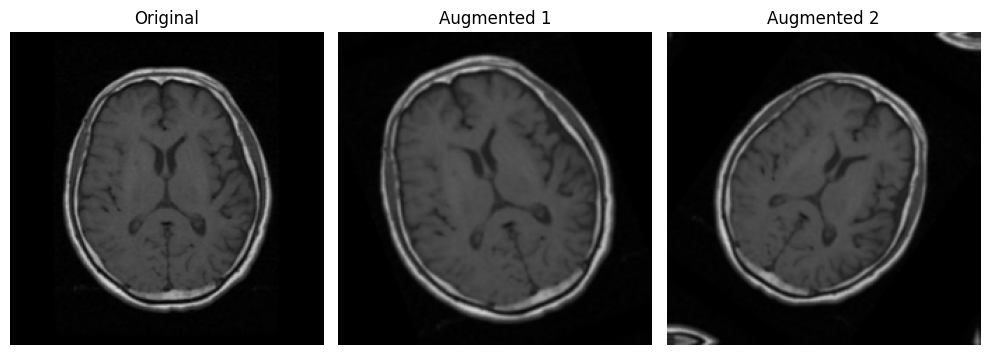

In [20]:
for images, labels in train_dataset.take(1):
    sample = images[0].numpy()

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

# Original image
axes[0].imshow(sample)
axes[0].set_title("Original")
axes[0].axis("off")

# Two augmented versions
for i in range(2):
    augmented = data_augmentation(
        tf.expand_dims(sample, axis=0), # to get 4D tensor (1,244,244,3)
        training=True                   # cuz Keras augmentation layers can process a batch of images.
    )[0].numpy()

    axes[i + 1].imshow(augmented)
    axes[i + 1].set_title(f"Augmented {i + 1}")
    axes[i + 1].axis("off")

plt.tight_layout()
plt.show()